In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)

# Build a realistic e-commerce order dataset across 12 months
dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
n_rows = 1200

order_dates = rng.choice(dates, size=n_rows)
customer_ids = [f"CUST_{i:03d}" for i in rng.integers(1, 221, size=n_rows)]
segments = rng.choice(
    ["VIP", "Loyal", "Occasional", "At-Risk"],
    size=n_rows,
    p=[0.18, 0.32, 0.32, 0.18],
)
categories = rng.choice(
    ["Electronics", "Fashion", "Home & Kitchen", "Books & Study"],
    size=n_rows,
    p=[0.30, 0.28, 0.24, 0.18],
)
regions = rng.choice(
    ["South", "West", "North", "East"],
    size=n_rows,
    p=[0.35, 0.25, 0.22, 0.18],
)
quantity = rng.integers(1, 6, size=n_rows)
unit_price = np.round(rng.uniform(199, 4999, size=n_rows), 2)
discount_pct = rng.choice([0, 5, 10, 15, 20], size=n_rows, p=[0.35, 0.25, 0.20, 0.12, 0.08])

df = pd.DataFrame({
    "order_id": [f"ORD_{i:04d}" for i in range(1, n_rows + 1)],
    "order_date": pd.to_datetime(order_dates),
    "customer_id": customer_ids,
    "segment": segments,
    "category": categories,
    "region": regions,
    "quantity": quantity,
    "unit_price": unit_price,
    "discount_pct": discount_pct,
})

df["gross_amount"] = np.round(df["quantity"] * df["unit_price"], 2)
df["revenue"] = np.round(df["gross_amount"] * (1 - df["discount_pct"] / 100), 2)
df["month"] = df["order_date"].dt.to_period("M").astype(str)

print("Shape:", df.shape)
df.head()

Shape: (1200, 12)


,order_id,order_date,customer_id,segment,category,region,quantity,unit_price,discount_pct,gross_amount,revenue,month
0,ORD_0001,2025-02-02,CUST_194,Occasional,Home & Kitchen,South,3,3471.72,0,10415.16,10415.16,2025-02
1,ORD_0002,2025-10-10,CUST_106,Occasional,Home & Kitchen,South,3,1164.78,0,3494.34,3494.34,2025-10
2,ORD_0003,2025-08-27,CUST_217,At-Risk,Home & Kitchen,West,1,2043.20,0,2043.20,2043.20,2025-08
3,ORD_0004,2025-06-10,CUST_168,Occasional,Books & Study,South,2,902.39,0,1804.78,1804.78,2025-06
4,ORD_0005,2025-06-08,CUST_144,VIP,Home & Kitchen,East,3,2852.21,10,8556.63,7700.97,2025-06


In [2]:
df.info()

print("\nMissing values:\n", df.isnull().sum())

total_revenue = df["revenue"].sum()
total_orders = df["order_id"].nunique()
unique_customers = df["customer_id"].nunique()
avg_order_value = df["revenue"].mean()

print(f"\nTotal Revenue: {total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Unique Customers: {unique_customers}")
print(f"Average Order Value (AOV): {avg_order_value:,.2f}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      1200 non-null   object        
 1   order_date    1200 non-null   datetime64[ns]
 2   customer_id   1200 non-null   object        
 3   segment       1200 non-null   object        
 4   category      1200 non-null   object        
 5   region        1200 non-null   object        
 6   quantity      1200 non-null   int64         
 7   unit_price    1200 non-null   float64       
 8   discount_pct  1200 non-null   int64         
 9   gross_amount  1200 non-null   float64       
 10  revenue       1200 non-null   float64       
 11  month         1200 non-null   object        
dtypes: datetime64[ns](1), float64(3), int64(2), object(6)
memory usage: 112.6+ KB

Missing values:
 order_id        0
order_date      0
customer_id     0
segment         0
category        0
re

In [3]:
monthly_trends = (
    df.groupby("month", as_index=False)
    .agg(
        orders=("order_id", "count"),
        active_customers=("customer_id", "nunique"),
        revenue=("revenue", "sum"),
    )
    .sort_values("month")
)
monthly_trends["mom_growth_pct"] = (monthly_trends["revenue"].pct_change() * 100).round(2)

print("Monthly Revenue Trends:\n", monthly_trends)

segment_summary = (
    df.groupby("segment", as_index=False)
    .agg(
        customers=("customer_id", "nunique"),
        orders=("order_id", "count"),
        total_revenue=("revenue", "sum"),
        avg_order_value=("revenue", "mean"),
    )
    .sort_values("total_revenue", ascending=False)
)
segment_summary["revenue_share_pct"] = (
    segment_summary["total_revenue"] / total_revenue * 100
).round(2)

print("\nCustomer Segment Performance:\n", segment_summary.round(2))

Monthly Revenue Trends:
       month  orders  active_customers    revenue  mom_growth_pct
0   2025-01      90                74  653597.11             NaN
1   2025-02     115                89  787272.72           20.45
2   2025-03      89                74  666307.09          -15.37
3   2025-04      96                71  732484.02            9.93
4   2025-05      76                66  530895.94          -27.52
5   2025-06     116                88  849423.33           60.00
6   2025-07     108                87  826007.28           -2.76
7   2025-08     103                86  713416.35          -13.63
8   2025-09     100                83  662368.88           -7.16
9   2025-10     111                87  699195.35            5.56
10  2025-11      86                70  649730.05           -7.07
11  2025-12     110                89  903968.40           39.13

Customer Segment Performance:
       segment  customers  orders  total_revenue  avg_order_value  \
1       Loyal        185     4

In [4]:
snapshot_date = df["order_date"].max() + pd.Timedelta(days=1)

cust_rf = (
    df.groupby(["customer_id", "segment"], as_index=False)
    .agg(
        last_order_date=("order_date", "max"),
        order_count=("order_id", "count"),
        total_spend=("revenue", "sum"),
    )
)
cust_rf["recency_days"] = (snapshot_date - cust_rf["last_order_date"]).dt.days

# Flag customers with > 90 days since last order and <= 2 orders as high churn risk
cust_rf["churn_risk"] = np.where(
    (cust_rf["recency_days"] > 90) & (cust_rf["order_count"] <= 2),
    "High Churn Risk",
    "Active / Healthy",
)

print("Churn Risk Breakdown:\n", cust_rf["churn_risk"].value_counts())
print("\nChurn Risk by Segment:\n", pd.crosstab(cust_rf["segment"], cust_rf["churn_risk"]))

Churn Risk Breakdown:
 churn_risk
High Churn Risk     322
Active / Healthy    312
Name: count, dtype: int64

Churn Risk by Segment:
 churn_risk  Active / Healthy  High Churn Risk
segment                                      
At-Risk                   60               75
Loyal                    105               80
Occasional                96               81
VIP                       51               86


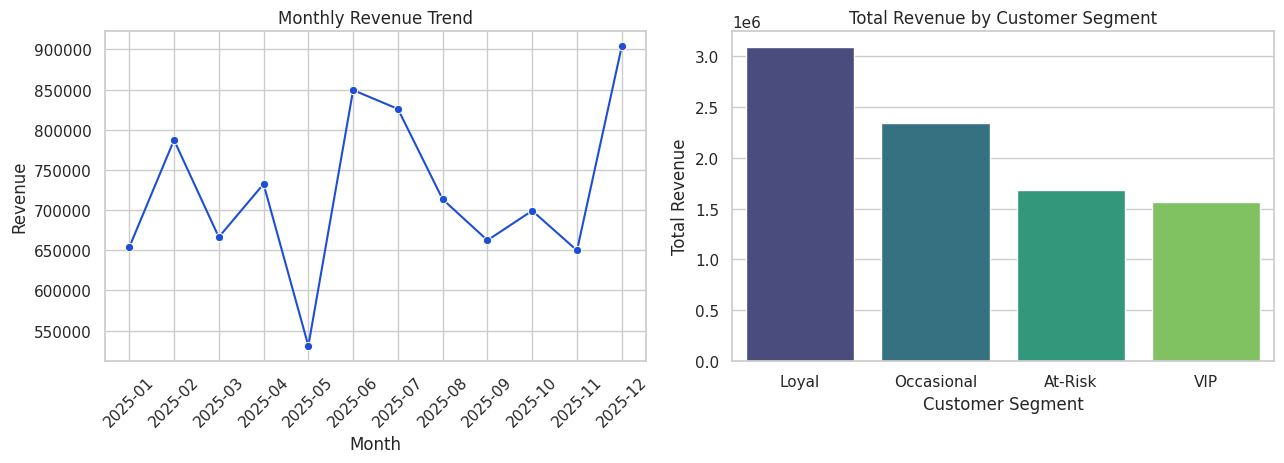

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.lineplot(
    data=monthly_trends,
    x="month",
    y="revenue",
    marker="o",
    color="#1D4ED8",
    ax=axes[0],
)
axes[0].set_title("Monthly Revenue Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(
    data=segment_summary,
    x="segment",
    y="total_revenue",
    hue="segment",
    palette="viridis",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Total Revenue by Customer Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Total Revenue")

plt.tight_layout()
plt.show()